# prompting_arm — negative-prompt calibration
Engine identical to prompting_arm; only negative_prompt varies, instruction held at baseline.
Conditions: n_empty (negative=""), n_contrastive (shipped filter + domain failure terms from baseline SC rationales), n_filler (shipped filter + length-matched neutral terms).
Scored against the original instruction via score_runs; compared via compare_runs. Sampler frozen at baseline values.

## 1. Repo

In [ ]:
import os, subprocess, sys
REPO = "/content/OmniGen2"
if not os.path.isdir(REPO):
    subprocess.run(["git","clone","https://github.com/VectorSpaceLab/OmniGen2.git",REPO], check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"], cwd=REPO, check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-U","huggingface_hub[hf_xet]>=0.30.0,<1.0"], check=True)
    print("installed.")
else:
    print("OmniGen2 already present.")
sys.path.insert(0, REPO)
os.chdir(REPO)

installed.


## 2. Drive, run config

In [ ]:
from google.colab import drive, userdata
import os
drive.mount("/content/drive")
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

DRIVE   = "/content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data"
DATASET = "screen"        # screen_small | screen | test
RUN     = "n_empty"   # fixed for this notebook; key into RUNS (section 5)

GEN = f"{DRIVE}/gen/{DATASET}/{RUN}"
os.makedirs(GEN, exist_ok=True)
n_have = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"data   : {DRIVE}")
print(f"output : {GEN}")
print(f"already generated: {n_have}")

Mounted at /content/drive
data   : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data
output : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/screen/n_empty
already generated: 0


## 3. Images, split files

In [ ]:
import subprocess, json
IMGS, EXPECTED = "/content/imgs", 37063
TAR = f"{DRIVE}/imgs_subset.tar"
def n_files(d): return sum(len(f) for _,_,f in os.walk(d)) if os.path.isdir(d) else 0
if n_files(IMGS) < EXPECTED:
    os.makedirs(IMGS, exist_ok=True)
    subprocess.run(f'cp "{TAR}" /content/imgs_subset.tar && tar -xf /content/imgs_subset.tar -C {IMGS}', shell=True, check=True)
    print("restored", n_files(IMGS), "/", EXPECTED)
    assert n_files(IMGS) >= EXPECTED, "restore incomplete"
else:
    print("images complete:", n_files(IMGS))

for s in ["train","val","test","screen","screen_small"]:
    src = f"{DRIVE}/{s}.jsonl"
    if os.path.exists(src) and not os.path.exists(f"/content/{s}.jsonl"):
        subprocess.run(["cp", src, f"/content/{s}.jsonl"])

rows = [json.loads(l) for l in open(f"/content/{DATASET}.jsonl", encoding="utf-8")]
missing = [p for r in rows for p in r["input_images"] if not os.path.exists(os.path.join(IMGS, p))]
assert not missing, f"{len(missing)} reference images missing, first: {missing[:3]}"
print(f"{DATASET}: {len(rows)} rows, all reference images present")

restored 37063 / 37063
screen: 302 rows, all reference images present


## 4. Model

In [ ]:
import torch
from accelerate import Accelerator
from omnigen2.pipelines.omnigen2.pipeline_omnigen2 import OmniGen2Pipeline
from omnigen2.models.transformers.transformer_omnigen2 import OmniGen2Transformer2DModel

MODEL = "OmniGen2/OmniGen2"
accelerator = Accelerator(mixed_precision="bf16")
dtype = torch.bfloat16

pipe = OmniGen2Pipeline.from_pretrained(MODEL, torch_dtype=dtype, trust_remote_code=True)
pipe.transformer = OmniGen2Transformer2DModel.from_pretrained(MODEL, subfolder="transformer", torch_dtype=dtype)
pipe = pipe.to(accelerator.device)
print("pipeline ready on", accelerator.device)

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/content/OmniGen2/omnigen2/models/attention_processor.py:33: UserWarning: Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance")
/content/OmniGen2/omnigen2/models/transformers/block_lumina2.py:37: UserWarning: Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance")


model_index.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

chat_template.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Expected types for transformer: (<class 'omnigen2.models.transformers.transformer_omnigen2.OmniGen2Transformer2DModel'>,), got <class 'diffusers_modules.local.transformer_omnigen2.OmniGen2Transformer2DModel'>.


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

pipeline ready on cuda


## 5. Engine and run table

In [ ]:
from PIL import Image, ImageOps
import torch

# shipped default from inference.py and omnicontext/inference.py; quality filter, not a domain negative
NEG = ("(((deformed))), blurry, over saturation, bad anatomy, disfigured, poorly drawn face, mutation, mutated, "
       "(extra_limb), (ugly), (poorly drawn hands), fused fingers, messy drawing, broken legs censor, censored, censor_bar")

def load_inputs(paths, max_side=512):   # refs downscaled; output size fixed at 512 via align_res=False
    out = []
    for p in paths:
        im = ImageOps.exif_transpose(Image.open(p).convert("RGB"))
        w, h = im.size
        s = max_side / max(w, h)
        if s < 1: w, h = int(w*s), int(h*s)
        w, h = max(16, (w//16)*16), max(16, (h//16)*16)
        out.append(im.resize((w, h), Image.LANCZOS))
    return out

def generate(instruction, input_images=None, negative=NEG, seed=0, steps=50, text_g=5.0, image_g=2.0, size=512):
    gen = torch.Generator(device=accelerator.device).manual_seed(seed)
    res = pipe(prompt=instruction, input_images=input_images,
               width=size, height=size, num_inference_steps=steps, max_sequence_length=1024,
               text_guidance_scale=text_g, image_guidance_scale=image_g, cfg_range=(0.0, 1.0),
               negative_prompt=negative, num_images_per_prompt=1, generator=gen, output_type="pil",
               align_res=False)
    return res.images[0]

# domain failure terms ranked from baseline SC rationales: shape 59%, color 58%, texture/logo/markings 50%, identity 37%, missing 29%
CONTRAST = ("wrong shape, distorted proportions, altered color, incorrect color, missing details, "
            "wrong logo, altered texture, missing markings, mismatched object, missing subject")
# neutral overlay/capture-artifact terms, orthogonal to the tested failure modes; term-count-matched to CONTRAST, 10 each (section 5b)
FILLER = ("faint watermark, digital signature, corner timestamp, printed caption, copyright notice, "
          "username tag, page border, thin frame, dark vignette, lens flare")

# one entry per condition; only negative_prompt varies, instruction held at baseline
RUNS = {
    "baseline":      dict(instruction=lambda r: r["instruction"], negative=NEG),
    "n_empty":       dict(instruction=lambda r: r["instruction"], negative=""),
    "n_contrastive": dict(instruction=lambda r: r["instruction"], negative=NEG + ", " + CONTRAST),
    "n_filler":      dict(instruction=lambda r: r["instruction"], negative=NEG + ", " + FILLER),
}

cfg = RUNS[RUN]
_probe = {"instruction": "<probe>", "input_images": []}
print(f"run '{RUN}'")
print(f"  instruction : {'unchanged' if cfg['instruction'](_probe) == '<probe>' else 'transformed'}")
_neg = cfg["negative"]
print(f"  negative    : {'empty' if _neg=='' else 'shipped default' if _neg==NEG else 'shipped + appended terms'}")
print(f"  sampler     : 50 steps, text_g=5.0, image_g=2.0, cfg_range=(0,1), seed 0, 512x512  (fixed across all conditions)")

run 'n_empty'
  instruction : unchanged
  negative    : empty
  sampler     : 50 steps, text_g=5.0, image_g=2.0, cfg_range=(0,1), seed 0, 512x512  (fixed across all conditions)


## 5b. Length-match check
Contrastive and filler negatives must match in Qwen tokens so the filler isolates content, not length.

In [ ]:
# contrastive vs filler appended spans, matched in Qwen tokens (pipe.processor.tokenizer)
tok = pipe.processor.tokenizer
lc, lf = len(tok(CONTRAST).input_ids), len(tok(FILLER).input_ids)
print(f"appended span tokens - contrastive {lc}, filler {lf}, diff {abs(lc - lf)}")
assert abs(lc - lf) <= 3, f"filler not length-matched ({lc} vs {lf}); adjust FILLER"
print("length-matched (<=3 tokens)")

appended span tokens - contrastive 30, filler 31, diff 1
length-matched (<=3 tokens)


## 6. Smoke — 3 rows

  0%|          | 0/50 [00:00<?, ?it/s]

row 0: 1 ref(s), output (512, 512), 28.7s


  0%|          | 0/50 [00:00<?, ?it/s]

row 1: 1 ref(s), output (512, 512), 20.3s


  0%|          | 0/50 [00:00<?, ?it/s]

row 2: 1 ref(s), output (512, 512), 18.5s


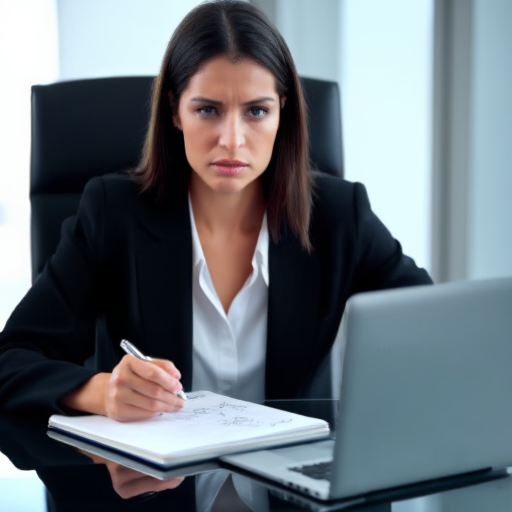

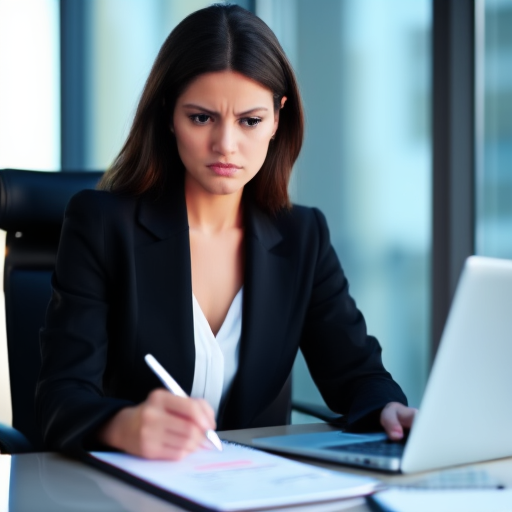

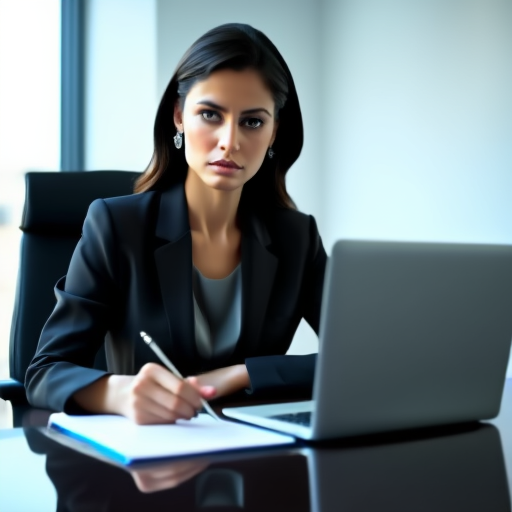

In [ ]:
import time
for i in range(3):
    r = rows[i]
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    t = time.time()
    img = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
    print(f"row {i}: {len(refs)} ref(s), output {img.size}, {time.time()-t:.1f}s")
    assert img.size == (512, 512), f"expected 512x512, got {img.size}"
    img.save(f"/content/smoke_{i}.png")

from IPython.display import display
for i in range(3):
    display(Image.open(f"/content/smoke_{i}.png"))

## 7. Full pass (resumable)

In [ ]:
import time
done, t0 = 0, time.time()
for i, r in enumerate(rows):
    out = f"{GEN}/{i:05d}.png"
    if os.path.exists(out):
        continue
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    img = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
    assert img.size == (512, 512), (i, img.size)
    img.save(out)
    done += 1
    if done % 10 == 0:
        print(f"generated {done} (at row {i+1}/{len(rows)}), {(time.time()-t0)/done:.1f}s/img")

total = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"\n{DATASET}/{RUN}: {total}/{len(rows)} images in {GEN}")
assert total == len(rows), "incomplete"

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

...

  0%|          | 0/50 [00:00<?, ?it/s]

generated 300 (at row 300/302), 23.5s/img


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]


screen/n_empty: 302/302 images in /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/screen/n_empty


In [ ]:
# manifest: provenance for the images in GEN. Written only when this session generated some,
# so a skip-through or resumed run cannot stamp the wrong GPU onto images made earlier.
if not done:
    print(f"no images generated this session; {GEN}/manifest.json left as-is")
else:
    import json, time, subprocess, torch
    man = {
        "dataset": DATASET, "run": RUN,
        "n_images": len([f for f in os.listdir(GEN) if f.endswith(".png")]),
        "gpu": torch.cuda.get_device_name(0),
        "driver": subprocess.run("nvidia-smi --query-gpu=driver_version --format=csv,noheader",
                                 shell=True, capture_output=True, text=True).stdout.strip(),
        "torch": torch.__version__, "cuda": torch.version.cuda, "model": MODEL,
        "sampler": dict(steps=50, text_guidance_scale=5.0, image_guidance_scale=2.0,
                        cfg_range=[0.0, 1.0], max_sequence_length=1024, seed=0,
                        size=512, align_res=False),
        "negative_prompt": cfg["negative"],
        "instruction_row0": cfg["instruction"](rows[0]),
        "bit_reproducible": False,
        "written": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    with open(f"{GEN}/manifest.json", "w") as f:
        json.dump(man, f, indent=2)
    print("manifest written:", f"{GEN}/manifest.json")

manifest written: /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/screen/n_empty/manifest.json


## 8. Determinism (off — floor inherited from baseline)
sigma_gen is a pipeline property, measured once on baseline; variants inherit it. Set RUN_DETERMINISM=True only to re-measure.

In [ ]:
# fixed-seed reproducibility. One-time: the floor is a pipeline property, not a per-config one.
# Cross-session: run on a fresh runtime so section 7 skips and the reruns come from a different session.
RUN_DETERMINISM = False  # floor already measured on baseline

if RUN_DETERMINISM:
    import numpy as np, json, time, subprocess
    N_DET = len(rows)                      # full set: sizes sigma_gen and tests for run-to-run bias
    RERUN = f"{DRIVE}/gen/{DATASET}/{RUN}__rerun"
    os.makedirs(RERUN, exist_ok=True)

    # rows are grouped by target, so a prefix would sit in few scenes; step through instead
    idx = list(range(0, len(rows), max(1, len(rows) // N_DET)))[:N_DET]
    print(f"determinism subset: {len(idx)} rows across {len({rows[i]['output_image'] for i in idx})} targets")

    identical, diffs, made, t0 = 0, [], 0, time.time()
    for i in idx:
        out = f"{RERUN}/{i:05d}.png"
        if os.path.exists(out):                      # resumable: 302 rows is ~1.9 h
            img2 = Image.open(out).convert("RGB")
        else:
            r = rows[i]
            refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
            img2 = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
            assert img2.size == (512, 512), (i, img2.size)
            img2.save(out); made += 1
            if made % 10 == 0:
                print(f"  regenerated {made}, {(time.time()-t0)/made:.1f}s/img")
        a = np.array(Image.open(f"{GEN}/{i:05d}.png").convert("RGB")).astype(np.int16)
        b = np.array(img2.convert("RGB")).astype(np.int16)
        if np.array_equal(a, b):
            identical += 1
        else:
            d = np.abs(a - b)
            diffs.append((i, int(d.max()), float(d.mean()), float((d > 0).mean())))

    n = len(idx)
    print(f"\npixel-identical: {identical}/{n}")
    if diffs:
        print(f"{'row':>5s} {'max|d|':>7s} {'mean|d|':>8s} {'px changed':>11s}")
        for i, mx, mn, frac in diffs[:10]:
            print(f"{i:>5d} {mx:>7d} {mn:>8.3f} {frac:>10.1%}")

    man = {
        "dataset": DATASET, "run": f"{RUN}__rerun", "n_images": len(idx),
        "gpu": torch.cuda.get_device_name(0),
        "driver": subprocess.run("nvidia-smi --query-gpu=driver_version --format=csv,noheader",
                                 shell=True, capture_output=True, text=True).stdout.strip(),
        "torch": torch.__version__, "cuda": torch.version.cuda, "model": MODEL,
        "sampler": dict(steps=50, text_guidance_scale=5.0, image_guidance_scale=2.0,
                        cfg_range=[0.0, 1.0], max_sequence_length=1024, seed=0,
                        size=512, align_res=False),
        "negative_prompt": cfg["negative"],
        "instruction_row0": cfg["instruction"](rows[0]),
        "regeneration_of": RUN, "cross_session": True,
        "pixel_identical": f"{identical}/{n}", "bit_reproducible": identical == n,
        "written": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    with open(f"{RERUN}/manifest.json", "w") as f:
        json.dump(man, f, indent=2)
    print("manifest written:", f"{RERUN}/manifest.json")
else:
    print("RUN_DETERMINISM=False — skipped.")

RUN_DETERMINISM=False — skipped.
